# Bài tập thực hành 2
Xây dựng mô hình từ giải thuật SVM trên dữ liệu các con thú trong rừng.

## Khai báo thư viện

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

## Nạp dữ liệu và kiểm tra

In [11]:
df = pd.read_csv("data/data.csv")
df.columns = df.columns.str.strip()

print(df.head())
print(df.shape)
print(df.columns.tolist())
print(df.isna().sum())

  AnimalName symptoms1             symptoms2 symptoms3    symptoms4  \
0        Dog     Fever              Diarrhea  Vomiting  Weight loss   
1        Dog     Fever              Diarrhea  Coughing    Tiredness   
2        Dog     Fever              Diarrhea  Coughing     Vomiting   
3        Dog     Fever  Difficulty breathing  Coughing     Lethargy   
4        Dog     Fever              Diarrhea  Coughing     Lethargy   

     symptoms5 Dangerous  
0  Dehydration       Yes  
1        Pains       Yes  
2     Anorexia       Yes  
3     Sneezing       Yes  
4     Blue Eye       Yes  
(871, 7)
['AnimalName', 'symptoms1', 'symptoms2', 'symptoms3', 'symptoms4', 'symptoms5', 'Dangerous']
AnimalName    0
symptoms1     0
symptoms2     0
symptoms3     0
symptoms4     0
symptoms5     0
Dangerous     2
dtype: int64


In [12]:
target_col = "Dangerous"

df = df.replace(r"^\s*$", np.nan, regex=True)
df = df.dropna(subset=[target_col])

X = df.drop(columns=[target_col])
y = df[target_col].astype(str).str.strip().str.lower()

print("Các lớp cần dự đoán:")
print(y.value_counts())

Các lớp cần dự đoán:
Dangerous
yes    849
no      20
Name: count, dtype: int64


## Chia dữ liệu

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


## Huấn luyện SVM

In [14]:

svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced"
    ))
])

svm_model.fit(X_train, y_train)
print("Đã huấn luyện xong SVM.")

Đã huấn luyện xong SVM.


Accuracy: 1.0
              precision    recall  f1-score   support

          no       1.00      1.00      1.00         4
         yes       1.00      1.00      1.00       170

    accuracy                           1.00       174
   macro avg       1.00      1.00      1.00       174
weighted avg       1.00      1.00      1.00       174



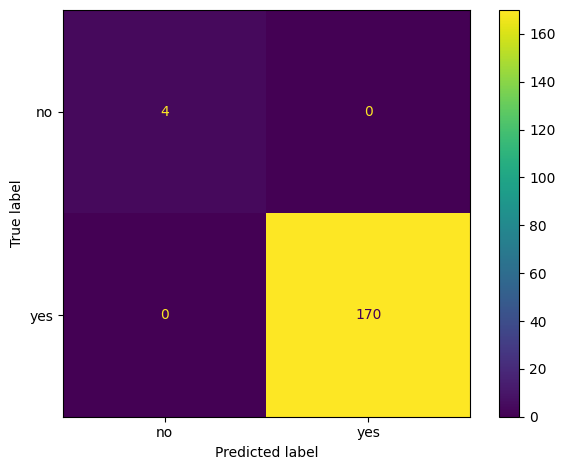

In [15]:
y_pred = svm_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.tight_layout()
plt.show()